# comp_ew の市場頑健性

`comp_ew` は全期間で Q5 EW 超過 13.0%・IC 0.065 と強いが、平均の強さとは別に「どんな市場で効かなくなるか」を把握しておきたい。
`market_basics` の 03（状態変数）と 05（ファクターの時系列）では主にロングショート（Q5−Q1）で、ストレス後の反発や上昇月に弱いことを見た。
ここではロングオンリーの指標を主役にして、市場環境・サブユニバース・時期を横断的に切り、**頑健な部分と脆い部分を一覧にする**。

**問い**

1. 市場の方向（上昇 / 下落、弱気相場、反発）で、選択力（Q5 − ユニバース EW）は保たれるか。BM 比（Q5 − BM）の負けは構造（サイズの賭け）とシグナルのどちらか
2. 市場構造（サイズサイクル、相場の広がり、超大型株の独走、横断面の分散）で効きが変わるか
3. 月末に分かるリスク状態（ボラ、相関、ブレス、52 週高安、出来高）で効きが変わるか（`03` の再確認をロングオンリーで）
4. 為替（INR 安 = FPI の売り）や個別のイベント（GFC、テーパー、廃貨、IL&FS、COVID、2024–25 の調整など）でどうだったか
5. サイズ区分・セクター・BM ユニバース（大型 + 中型）の中でも効くか
6. どのスタイル環境（バリュー相場、モメンタムの崩れ、小型優位）で負けるか

**指標**（月次、`drtn` = 配当込み。リターンの月で日付を付ける）

| 指標 | 意味 |
| --- | --- |
| `Q5−BM` | Q5（上位 20%、等ウェイト）− MSCI India。実際のロングオンリーの成績に最も近い |
| `Q5−EW` | Q5 − ユニバース等ウェイト（5 分位の平均）。サイズの構造的な賭けを除いた**選択力** |
| `CW Q5−BM` | Q5（時価総額ウェイト、1 銘柄 5% 上限）− BM |
| `Q5−Q1` | ロングショート |
| `IC` | 月末のスコアと翌月リターンの順位相関（翌月 = リターンの月に日付を合わせる） |

**規約**: 期間 2008-02〜2026-07（リターンの月）。税控除前の指標はバーンインなし（2008 年の暴落を含めるため）、税控除後は既存の規約（バーンイン 12 か月）で全期間の参考値のみ。
条件の状態は 2 種類で、**同じ月の状態**（その月に何が起きていたか、記述用、全期間の三分位）と、**月末に確定する状態**（前月末の値、拡大窓の三分位 = その時点で分かる区分）。
t 値は Newey–West（ラグ 6）、差の t は 2 群の平均差の単純な t。状態変数は `scripts/market_states.py`。

In [1]:
import sys
from pathlib import Path

import japanize_matplotlib  # noqa: F401  日本語ラベル用
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../../scripts").resolve()))
from build_market_panel import SECTOR_NAMES, load_panel
from market_states import lagged_states, same_month_states

from alphaeval import (
    InputStore,
    compute_alpha_report,
    india_tax_schedule,
    information_coefficient,
    summary_table,
)
from alphaeval.panel import forward_returns

pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

INPUT_ROOT = "../../input/msci_india_imi"
START, END = 200801, 202606
BENCHMARK = "msci_india"
RETURN_KINDS = {"drtn": "rtn", "srtn": "srtn"}
CW_MAX_WEIGHT = 0.05
OOS_START = "2018-01-01"

store = InputStore(INPUT_ROOT)
univ = store.universe(START, END)
bm = store.benchmark(BENCHMARK, START, END)
comp = (
    store.alpha("composite/comp_ew", START, END)
    .reindex(index=univ.index, columns=univ.columns)
    .where(univ.notna())
)
returns = {k: store.returns("GEMLT", c, START, 202607) for k, c in RETURN_KINDS.items()}
fwd = {k: forward_returns(r, 1) for k, r in returns.items()}
size_seg = store.alpha("attributes/size", START, END).reindex(
    index=univ.index, columns=univ.columns
)
gics = store.alpha("attributes/gics", START, END).reindex(
    index=univ.index, columns=univ.columns
)
sector = np.floor(gics / 1e6)

rep = compute_alpha_report(
    "comp_ew", comp, univ, bm, returns, cw_max_weight=CW_MAX_WEIGHT, burn_in=0
)
rep_tax = compute_alpha_report(
    "comp_ew",
    comp,
    univ,
    bm,
    returns,
    cw_max_weight=CW_MAX_WEIGHT,
    tax_schedule=india_tax_schedule("trust"),
    cost_buy=0.0015,
    cost_sell=0.0025,
    burn_in=12,
    tax_kind="drtn",
)


def shift_month(s: pd.Series) -> pd.Series:
    out = s.copy()
    out.index = out.index + pd.offsets.MonthEnd(1)
    return out


def metrics(kind: str) -> pd.DataFrame:
    q = rep.quantile_returns[kind]
    return pd.DataFrame(
        {
            "Q5−BM": rep.series["ew_excess"][kind],
            "Q5−EW": q[rep.top] - q.drop(columns="spread").mean(axis=1),
            "CW Q5−BM": rep.series["cw_excess"][kind],
            "Q5−Q1": rep.series["spread"][kind],
            "IC": shift_month(rep.series["ic"][kind]),
        }
    ).dropna(how="all")


M = metrics("drtn")
MS = metrics("srtn")
METRICS = list(M.columns)
print("月数:", len(M), M.index[0].date(), "〜", M.index[-1].date())

panel = load_panel("../../data/market_panel", fields=("ret", "close", "value"))
lag_raw = lagged_states(panel)
now = same_month_states(panel, "../../data/fx.csv").reindex(M.index)
lag = shift_month(lag_raw).reindex(M.index)  # 前月末の状態 → 当月のリターン
bm_implied = rep.quantile_returns["drtn"][rep.top] - rep.series["ew_excess"]["drtn"]
print(
    "確認: レポートの BM リターンと market_states の mkt の相関（同じ月）",
    round(float(bm_implied.corr(now["mkt"])), 4),
)

月数: 222 2008-02-29 〜 2026-07-31


確認: レポートの BM リターンと market_states の mkt の相関（同じ月） 0.9999


In [2]:
def nw_t(x: pd.Series, lags: int = 6) -> float:
    x = pd.Series(x).dropna().to_numpy()
    n = len(x)
    if n < 6:
        return np.nan
    e = x - x.mean()
    s = (e**2).sum() / n
    for L in range(1, min(lags, n - 1) + 1):
        s += 2 * (1 - L / (lags + 1)) * (e[L:] * e[:-L]).sum() / n
    return x.mean() / np.sqrt(s / n)


def scale(m: str) -> float:
    return 1.0 if m.startswith("IC") else 12.0


def summarize(x: pd.DataFrame) -> pd.Series:
    out = {}
    for m in x.columns:
        out[m] = x[m].mean() * scale(m)
        out[m + " t"] = nw_t(x[m])
    out["月数"] = len(x)
    return pd.Series(out)


def full_terciles(s: pd.Series) -> pd.Series:
    q1, q2 = s.quantile([1 / 3, 2 / 3])
    return pd.Series(np.where(s <= q1, 1, np.where(s > q2, 3, 2)), index=s.index).where(
        s.notna()
    )


def expanding_terciles(s: pd.Series, min_obs: int = 36) -> pd.Series:
    out = pd.Series(np.nan, index=s.index)
    vals = s.to_numpy()
    for i in range(len(s)):
        hist = vals[: i + 1]
        hist = hist[np.isfinite(hist)]
        if len(hist) < min_obs or not np.isfinite(vals[i]):
            continue
        q1, q2 = np.quantile(hist, [1 / 3, 2 / 3])
        out.iloc[i] = 1 if vals[i] <= q1 else (3 if vals[i] > q2 else 2)
    return out


SCORE = []  # スコアカード用


def cond_table(
    name: str,
    groups: pd.Series,
    labels: dict,
    data: pd.DataFrame = M,
    record: bool = True,
) -> pd.DataFrame:
    rows = {}
    for g, lab in labels.items():
        idx = groups.index[groups == g]
        rows[lab] = summarize(data.reindex(idx).dropna(how="all"))
    tbl = pd.DataFrame(rows).T
    first, last = list(labels.values())[0], list(labels.values())[-1]
    diff = {}
    for m in data.columns:
        a = data[m].reindex(groups.index[groups == list(labels)[0]]).dropna()
        b = data[m].reindex(groups.index[groups == list(labels)[-1]]).dropna()
        se = np.sqrt(a.var() / len(a) + b.var() / len(b))
        diff[m] = (b.mean() - a.mean()) * scale(m)
        diff[m + " t"] = (b.mean() - a.mean()) / se
    tbl.loc[f"差（{last} − {first}）"] = pd.Series(diff)
    if record:
        body = tbl.iloc[:-1]
        SCORE.append(
            {
                "条件": name,
                "最悪 Q5−EW": body["Q5−EW"].min(),
                "最悪の区分": body["Q5−EW"].idxmin(),
                "最悪 Q5−BM": body["Q5−BM"].min(),
                "最悪 IC": body["IC"].min(),
                "Q5−EW > 0 の区分": f"{int((body['Q5−EW'] > 0).sum())}/{len(body)}",
                "Q5−EW 差 t": diff["Q5−EW t"],
                "Q5−BM 差 t": diff["Q5−BM t"],
            }
        )
    return tbl


def show(tbl: pd.DataFrame) -> None:
    cols = [c for c in tbl.columns if c != "月数"]
    fmt = tbl.copy()
    fmt[cols] = fmt[cols].astype(float).round(3)
    display(fmt)

## 1. 全体と時期の安定性

### 1.1 全体（drtn / srtn）と IS / OOS

In [3]:
rows = {
    "全期間 drtn": summarize(M),
    "IS（〜2017）drtn": summarize(M.loc[:"2017-12-31"]),
    "OOS（2018〜）drtn": summarize(M.loc[OOS_START:]),
    "全期間 srtn": summarize(MS),
    "OOS（2018〜）srtn": summarize(MS.loc[OOS_START:]),
}
show(pd.DataFrame(rows).T)
tb = summary_table({"comp_ew": rep_tax})
print(
    "参考（既存規約、2009-02〜）: 税控除後 Q5 EW 超過",
    round(float(tb[("drtn", "税控除後 Q5 EW 超過 (vs BM)")].iloc[0]), 3),
)

,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
全期間 drtn,0.121,4.653,0.096,6.533,0.094,4.621,0.174,5.436,0.064,7.354,222.0
IS（〜2017）drtn,0.140,4.505,0.103,4.814,0.119,5.534,0.181,3.534,0.075,5.636,119.0
OOS（2018〜）drtn,0.099,2.311,0.089,4.450,0.066,1.845,0.167,4.562,0.051,5.177,103.0
全期間 srtn,0.090,4.346,0.065,5.394,0.058,3.645,0.109,5.126,0.037,6.763,222.0
OOS（2018〜）srtn,0.096,3.086,0.055,2.911,0.042,1.631,0.106,3.747,0.031,4.050,103.0


参考（既存規約、2009-02〜）: 税控除後 Q5 EW 超過 0.085


### 1.2 暦年

各年の月次の和（IC は平均）。最後の行は「プラスの年の比率」。

In [4]:
yr = M.groupby(M.index.year).agg({m: ("mean" if m == "IC" else "sum") for m in METRICS})
yr["BM"] = now["mkt"].groupby(now.index.year).apply(lambda r: (1 + r).prod() - 1)
yr["EW−CW"] = now["size_spread"].groupby(now.index.year).sum()
hit = (yr[METRICS] > 0).mean().rename("プラスの年の比率")
display(pd.concat([yr.round(3), hit.to_frame().T.round(2)]))

,Q5−BM,Q5−EW,CW Q5−BM,Q5−Q1,IC,BM,EW−CW
2008,-0.012,0.056,0.031,0.053,0.031,-0.489,-0.060
2009,0.214,0.002,0.088,-0.032,0.028,0.941,0.224
2010,0.107,0.113,0.103,0.242,0.127,0.166,-0.017
2011,0.116,0.253,0.138,0.514,0.180,-0.254,-0.135
2012,0.128,0.050,0.129,0.035,0.058,0.302,0.059
2013,0.023,0.153,0.044,0.244,0.087,0.090,-0.112
2014,0.256,0.078,0.186,0.246,0.083,0.266,0.158
2015,0.145,0.111,0.129,0.254,0.062,-0.019,0.020
2016,0.169,0.111,0.093,0.126,0.044,0.010,0.049
2017,0.238,0.090,0.233,0.108,0.046,0.304,0.112


### 1.3 ローリング（36 か月）と最悪の 12 か月

36 か月の移動平均（年率）。下段は 12 か月の移動和（IC は移動平均）の最悪値。

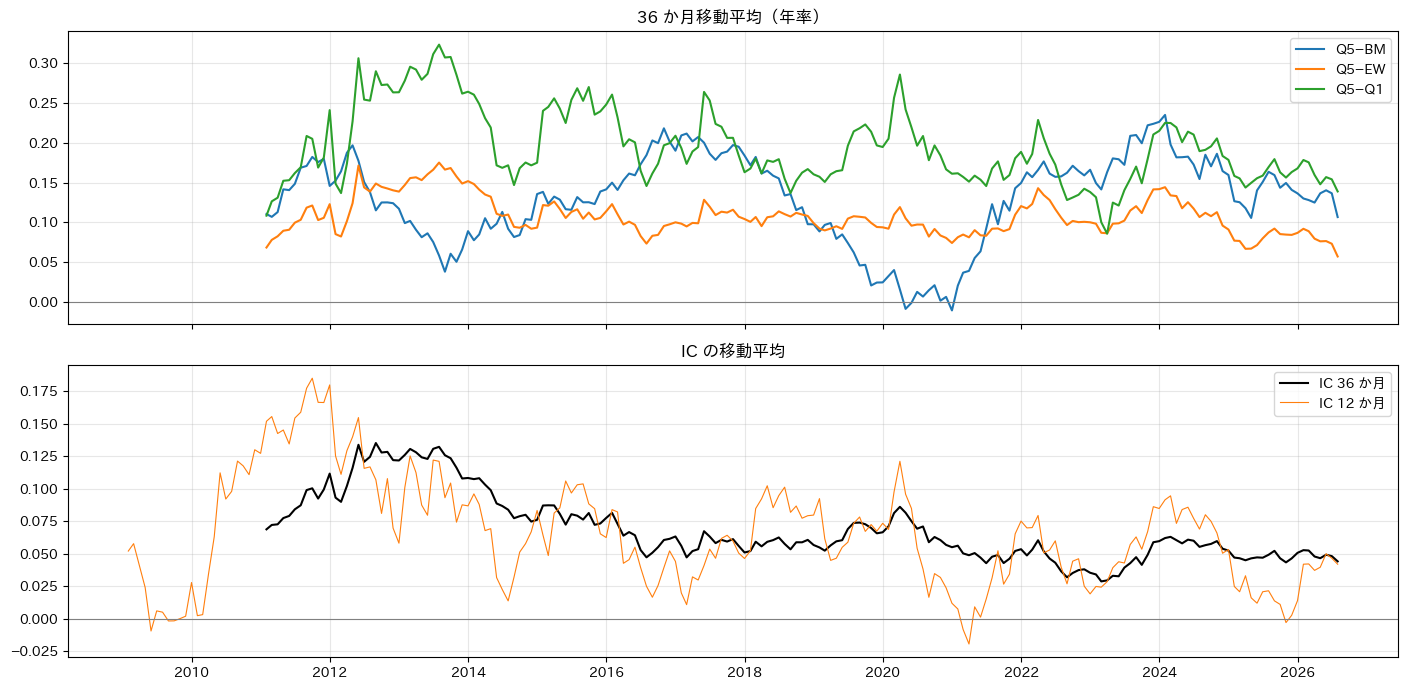

,最悪 12 か月,終了月,マイナスの窓の比率
Q5−BM,-0.165863,2019-04,0.153153
Q5−EW,-0.05753,2009-05,0.036036
CW Q5−BM,-0.138195,2019-04,0.157658
Q5−Q1,-0.166719,2009-11,0.081081
IC,-0.019435,2021-03,0.027027


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for m in ["Q5−BM", "Q5−EW", "Q5−Q1"]:
    axes[0].plot(M[m].rolling(36).mean() * 12, label=m)
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_title("36 か月移動平均（年率）")
axes[0].legend()
axes[1].plot(M["IC"].rolling(36).mean(), color="k", label="IC 36 か月")
axes[1].plot(M["IC"].rolling(12).mean(), color="C1", linewidth=0.8, label="IC 12 か月")
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_title("IC の移動平均")
axes[1].legend()
plt.tight_layout()
plt.show()
r12 = M[["Q5−BM", "Q5−EW", "CW Q5−BM", "Q5−Q1"]].rolling(12).sum()
r12["IC"] = M["IC"].rolling(12).mean()
worst = pd.DataFrame(
    {
        m: {
            "最悪 12 か月": r12[m].min(),
            "終了月": r12[m].idxmin().strftime("%Y-%m"),
            "マイナスの窓の比率": (r12[m] < 0).mean(),
        }
        for m in r12.columns
    }
).T
display(worst)

## 2. 市場の方向

### 2.1 BM の月次リターンの 5 分位（同じ月）

上昇が強い月ほど Q5−BM が負けるのは、Q5 が低ベータ・中小型に傾くため（構造）。選択力（Q5−EW）がどの分位でも正かを見る。

In [6]:
q = pd.qcut(now["mkt"], 5, labels=False) + 1
show(
    cond_table(
        "BM の月次リターン（5 分位、同月）",
        q,
        {1: "大きく下落", 2: "下落", 3: "横ばい", 4: "上昇", 5: "大きく上昇"},
    )
)

,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
大きく下落,0.054,1.032,0.215,6.031,0.099,2.274,0.496,6.270,0.153,5.852,45.0
下落,0.158,2.896,0.154,4.547,0.151,3.358,0.303,4.774,0.106,4.174,44.0
横ばい,0.146,2.649,0.125,4.037,0.113,2.948,0.226,3.488,0.072,3.936,44.0
上昇,0.190,3.888,0.089,3.759,0.110,2.529,0.157,2.849,0.038,2.816,44.0
大きく上昇,0.058,0.941,-0.101,-1.974,-0.000,-0.002,-0.307,-2.673,-0.048,-1.875,45.0
差（大きく上昇 − 大きく下落）,0.004,0.051,-0.316,-5.542,-0.099,-1.423,-0.803,-6.586,-0.201,-7.290,NaN


### 2.2 弱気相場・ドローダウン・反発（前月末の状態）

- `bear24`: 前月末に BM の過去 24 か月累積が負（`momentum_regime` と同じ判定）
- `drawdown`: 前月末の BM の高値からの下落率
- 反発: 前月末が弱気相場（`bear24`）で、当月の BM が上位 20% の上昇

In [7]:
show(
    cond_table(
        "弱気相場（bear24、前月末）", lag["bear24"], {0.0: "平常", 1.0: "弱気相場"}
    )
)
dd = pd.cut(
    lag["drawdown"], [-1, -0.2, -0.1, -0.03, 0.001], labels=[4, 3, 2, 1]
).astype(float)
show(
    cond_table(
        "ドローダウン（前月末）",
        dd,
        {1: "高値圏（> −3%）", 2: "−3〜−10%", 3: "−10〜−20%", 4: "< −20%"},
    )
)
up = now["mkt"] > now["mkt"].quantile(0.8)
reb = pd.Series(
    np.where(lag["bear24"] == 1, np.where(up, 3, 2), np.where(up, 1, 0)), index=M.index
).where(lag["bear24"].notna())
show(
    cond_table(
        "弱気相場 × 大幅上昇（反発）",
        reb,
        {
            0: "平常 × その他",
            1: "平常 × 大幅上昇",
            2: "弱気 × その他",
            3: "弱気 × 大幅上昇（反発）",
        },
    )
)

,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
平常,0.126,4.373,0.114,7.158,0.100,4.181,0.219,6.774,0.072,7.394,186.0
弱気相場,0.092,1.539,0.002,0.061,0.065,1.512,-0.058,-0.584,0.025,1.056,36.0
差（弱気相場 − 平常）,-0.034,-0.464,-0.112,-1.649,-0.034,-0.530,-0.278,-1.866,-0.047,-1.363,NaN


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
高値圏（> −3%）,0.184,4.858,0.138,7.436,0.154,5.262,0.275,5.932,0.084,6.351,93.0
−3〜−10%,0.070,2.272,0.070,3.677,0.058,2.405,0.135,3.495,0.044,3.319,63.0
−10〜−20%,0.137,3.401,0.126,2.700,0.086,1.584,0.220,2.233,0.094,2.815,41.0
< −20%,-0.013,-0.111,-0.043,-0.522,-0.025,-0.285,-0.177,-0.974,-0.010,-0.292,25.0
差（< −20% − 高値圏（> −3%））,-0.197,-1.924,-0.181,-1.991,-0.179,-2.126,-0.452,-2.309,-0.094,-2.390,NaN


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
平常 × その他,0.135,3.761,0.137,7.617,0.109,3.706,0.281,8.114,0.087,7.582,156.0
平常 × 大幅上昇,0.082,1.267,-0.006,-0.218,0.052,0.930,-0.103,-1.431,-0.007,-0.507,30.0
弱気 × その他,0.151,3.340,0.211,4.862,0.187,6.440,0.412,3.891,0.136,3.744,21.0
弱気 × 大幅上昇（反発）,0.011,0.102,-0.289,-4.679,-0.104,-1.221,-0.717,-4.806,-0.130,-3.740,15.0
差（弱気 × 大幅上昇（反発） − 平常 × その他）,-0.124,-0.927,-0.427,-4.000,-0.213,-1.814,-0.998,-4.279,-0.217,-4.628,NaN


## 3. 市場構造（同じ月）

- サイズサイクル: EW − CW（その月に中小型が勝ったか）
- 相場の広がり: BM に勝った銘柄の比率（狭い相場 = 一部の銘柄だけが上がる）
- 超大型株の独走: BM 上位 10 銘柄 − それ以外（時価総額加重）
- 横断面の分散: 銘柄リターンの横断面 SD（銘柄間の差がつく月か）

In [8]:
for col, name, labs in [
    (
        "size_spread",
        "サイズサイクル（EW − CW、同月）",
        {1: "大型優位", 2: "中立", 3: "中小型優位"},
    ),
    (
        "win_share",
        "相場の広がり（BM に勝った比率、同月）",
        {1: "狭い相場", 2: "中間", 3: "広い相場"},
    ),
    (
        "top10_minus_rest",
        "超大型株の独走（上位 10 − 他、同月）",
        {1: "上位 10 が負け", 2: "中立", 3: "上位 10 が独走"},
    ),
    ("csd", "横断面の分散（同月）", {1: "低分散", 2: "中間", 3: "高分散"}),
]:
    print(f"■ {name}")
    show(cond_table(name, full_terciles(now[col]), labs))

■ サイズサイクル（EW − CW、同月）


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
大型優位,-0.223,-5.097,0.161,4.573,-0.119,-3.380,0.381,5.897,0.120,6.299,74.0
中立,0.131,5.822,0.120,6.146,0.127,6.346,0.242,5.876,0.080,6.793,74.0
中小型優位,0.454,13.504,0.007,0.192,0.274,9.150,-0.099,-1.181,-0.007,-0.368,74.0
差（中小型優位 − 大型優位）,0.677,14.303,-0.154,-3.553,0.393,8.587,-0.480,-5.326,-0.127,-5.906,NaN


■ 相場の広がり（BM に勝った比率、同月）


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
狭い相場,-0.248,-8.180,0.123,4.026,-0.140,-5.821,0.300,5.359,0.097,6.256,74.0
中間,0.163,5.111,0.154,5.450,0.156,4.194,0.292,4.981,0.097,5.095,74.0
広い相場,0.447,12.953,0.012,0.326,0.266,10.332,-0.069,-0.834,-0.002,-0.104,74.0
差（広い相場 − 狭い相場）,0.696,16.502,-0.111,-2.754,0.405,9.984,-0.369,-4.317,-0.099,-4.768,NaN


■ 超大型株の独走（上位 10 − 他、同月）


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
上位 10 が負け,0.316,8.435,0.020,0.519,0.228,6.850,-0.030,-0.381,0.004,0.262,74.0
中立,0.154,5.043,0.111,4.624,0.139,5.626,0.200,3.575,0.081,5.742,74.0
上位 10 が独走,-0.109,-3.196,0.158,4.704,-0.084,-2.922,0.353,5.795,0.107,5.743,74.0
差（上位 10 が独走 − 上位 10 が負け）,-0.425,-7.387,0.138,3.162,-0.312,-6.563,0.383,4.237,0.103,4.753,NaN


■ 横断面の分散（同月）


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
低分散,0.064,1.514,0.081,5.553,0.078,2.407,0.155,5.973,0.066,5.393,74.0
中間,0.093,2.232,0.125,5.849,0.077,2.348,0.255,5.896,0.085,5.084,74.0
高分散,0.205,3.462,0.082,2.247,0.127,3.152,0.114,1.409,0.042,2.445,74.0
差（高分散 − 低分散）,0.140,2.123,0.001,0.024,0.048,0.899,-0.041,-0.418,-0.024,-1.046,NaN


## 4. 月末に分かるリスク状態（前月末、拡大窓の三分位）

`03_state_variables` ではロングショートと IC で「ストレス状態の翌月は効かない」を見た。ロングオンリーの指標でも同じかを確認する。
三分位は各時点までのデータだけで決めるので、運用のルールにそのまま使える区分。

In [9]:
for col, name, labs in [
    ("rv63", "市場ボラ 63 日", {1: "低ボラ", 2: "中", 3: "高ボラ"}),
    ("avg_corr", "平均ペア相関 63 日", {1: "低相関", 2: "中", 3: "高相関"}),
    ("breadth_200", "200 日線を上回る比率", {1: "ブレス低", 2: "中", 3: "ブレス高"}),
    (
        "hl52",
        "52 週高値 − 安値更新",
        {1: "安値更新が多い", 2: "中", 3: "高値更新が多い"},
    ),
    ("size_cyc", "サイズサイクル 12 か月", {1: "大型優位", 2: "中", 3: "中小型優位"}),
    ("value_shock", "売買代金ショック", {1: "出来高細る", 2: "中", 3: "出来高膨らむ"}),
]:
    print(f"■ {name}（前月末）")
    terc = shift_month(expanding_terciles(lag_raw[col])).reindex(M.index)
    show(cond_table(f"{name}（前月末）", terc, labs))

■ 市場ボラ 63 日（前月末）


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
低ボラ,0.134,3.807,0.135,7.316,0.124,4.896,0.268,6.830,0.090,8.057,149.0
中,0.091,1.919,0.034,1.273,0.041,1.077,0.047,0.666,0.023,1.436,47.0
高ボラ,0.100,1.099,-0.013,-0.238,0.017,0.322,-0.130,-0.985,-0.010,-0.384,26.0
差（高ボラ − 低ボラ）,-0.033,-0.356,-0.149,-1.879,-0.107,-1.365,-0.398,-2.380,-0.100,-2.986,NaN


■ 平均ペア相関 63 日（前月末）


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
低相関,0.143,3.882,0.126,7.159,0.131,4.824,0.246,6.137,0.084,9.623,131.0
中,0.044,0.889,0.059,1.366,0.028,0.664,0.130,1.522,0.055,2.162,59.0
高相関,0.170,2.567,0.043,1.189,0.066,1.368,-0.039,-0.440,0.002,0.084,32.0
差（高相関 − 低相関）,0.026,0.335,-0.083,-1.723,-0.065,-1.127,-0.286,-2.328,-0.082,-3.159,NaN


■ 200 日線を上回る比率（前月末）


...

,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
安値更新が多い,0.053,1.662,0.063,2.006,0.021,0.873,0.081,1.192,0.045,2.782,88.0
中,0.136,3.661,0.099,4.472,0.117,4.200,0.205,4.196,0.068,4.459,88.0
高値更新が多い,0.221,4.341,0.155,6.430,0.190,5.324,0.294,10.316,0.092,9.990,46.0
差（高値更新が多い − 安値更新が多い）,0.168,2.257,0.092,2.016,0.169,2.895,0.213,2.264,0.046,2.029,NaN


■ サイズサイクル 12 か月（前月末）


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
大型優位,0.036,0.667,0.059,2.431,0.014,0.376,0.088,1.106,0.044,2.378,29.0
中,0.087,2.952,0.080,3.155,0.053,2.235,0.140,2.610,0.058,4.053,102.0
中小型優位,0.185,6.429,0.126,6.933,0.165,7.014,0.241,7.307,0.077,8.546,91.0
差（中小型優位 − 大型優位）,0.149,1.987,0.066,1.603,0.152,2.550,0.152,1.418,0.033,1.269,NaN


■ 売買代金ショック（前月末）


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
出来高細る,0.083,1.858,0.094,3.346,0.065,1.832,0.152,2.726,0.060,3.549,71.0
中,0.058,1.177,0.107,4.906,0.077,1.899,0.203,3.717,0.070,4.557,68.0
出来高膨らむ,0.204,4.169,0.090,3.784,0.133,3.043,0.170,3.339,0.063,4.649,83.0
差（出来高膨らむ − 出来高細る）,0.121,1.855,-0.004,-0.099,0.067,1.296,0.019,0.197,0.004,0.165,NaN


## 5. 為替（同じ月）

USD/INR の月次変化（正 = INR 安）。INR 安の月は FPI の売り越しと重なりやすく、FPI が多く持つ大型株が売られる。

In [10]:
show(
    cond_table(
        "為替（USD/INR 変化、同月）",
        full_terciles(now["fx"]),
        {1: "INR 高", 2: "中", 3: "INR 安"},
    )
)

,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
INR 高,0.093,2.557,-0.019,-0.514,0.040,1.114,-0.090,-1.133,0.010,0.585,74.0
中,0.167,3.329,0.110,4.801,0.138,3.753,0.221,5.289,0.062,5.840,74.0
INR 安,0.101,2.219,0.197,6.298,0.104,2.497,0.392,6.426,0.120,5.732,74.0
差（INR 安 − INR 高）,0.008,0.129,0.217,5.359,0.065,1.226,0.482,5.406,0.109,4.870,NaN


## 6. イベント・局面

局面ごとの累積（月次の和、IC は平均）。期間はおおよその区切り。BM は期間の累積リターン。

,Q5−BM,Q5−EW,CW Q5−BM,Q5−Q1,IC,BM,EW−CW,月数
GFC 暴落,-0.038,0.113,0.034,0.177,0.058,-0.529,-0.131,13.0
2009 反発,0.241,-0.055,0.086,-0.156,-0.008,1.104,0.295,10.0
2011 インフレ・欧州危機,0.116,0.253,0.138,0.514,0.180,-0.254,-0.135,12.0
2013 テーパー,-0.009,0.096,0.017,0.150,0.120,0.001,-0.097,5.0
2014 モディ相場,0.256,0.078,0.186,0.246,0.083,0.266,0.158,12.0
2016 廃貨,-0.007,0.024,-0.020,0.041,0.063,-0.060,-0.025,2.0
2017 中小型ブーム,0.238,0.090,0.233,0.108,0.046,0.304,0.112,12.0
2018–19 狭い相場（IL&FS）,-0.133,0.175,-0.072,0.434,0.092,-0.001,-0.259,19.0
2020 コロナ暴落,-0.006,0.083,0.022,0.215,0.249,-0.264,-0.076,2.0
2020 コロナ反発,0.069,-0.064,-0.015,-0.244,-0.056,0.630,0.118,9.0


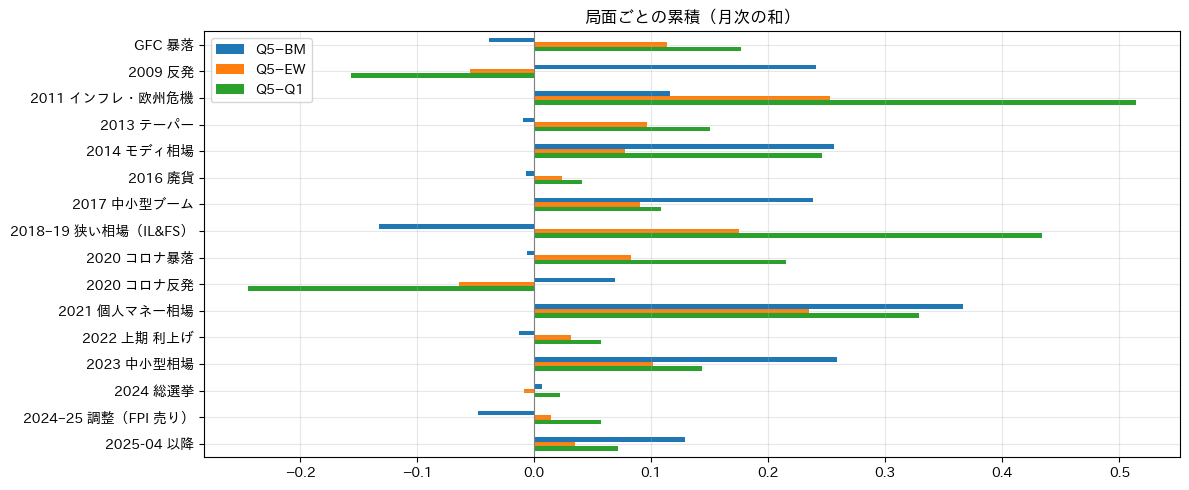

In [11]:
EPISODES = {
    "GFC 暴落": ("2008-02", "2009-02"),
    "2009 反発": ("2009-03", "2009-12"),
    "2011 インフレ・欧州危機": ("2011-01", "2011-12"),
    "2013 テーパー": ("2013-05", "2013-09"),
    "2014 モディ相場": ("2014-01", "2014-12"),
    "2016 廃貨": ("2016-11", "2016-12"),
    "2017 中小型ブーム": ("2017-01", "2017-12"),
    "2018–19 狭い相場（IL&FS）": ("2018-02", "2019-08"),
    "2020 コロナ暴落": ("2020-02", "2020-03"),
    "2020 コロナ反発": ("2020-04", "2020-12"),
    "2021 個人マネー相場": ("2021-01", "2021-12"),
    "2022 上期 利上げ": ("2022-01", "2022-06"),
    "2023 中小型相場": ("2023-04", "2023-12"),
    "2024 総選挙": ("2024-05", "2024-06"),
    "2024–25 調整（FPI 売り）": ("2024-10", "2025-03"),
    "2025-04 以降": ("2025-04", "2026-07"),
}
rows = {}
for name, (a, b) in EPISODES.items():
    x = M.loc[a:b]
    row = {m: (x[m].mean() if m == "IC" else x[m].sum()) for m in METRICS}
    row["BM"] = (1 + now["mkt"].loc[a:b]).prod() - 1
    row["EW−CW"] = now["size_spread"].loc[a:b].sum()
    row["月数"] = len(x)
    rows[name] = row
ep = pd.DataFrame(rows).T
display(ep.round(3))
fig, ax = plt.subplots(figsize=(12, 5))
ep[["Q5−BM", "Q5−EW", "Q5−Q1"]].plot.barh(ax=ax)
ax.axvline(0, color="gray", linewidth=0.8)
ax.invert_yaxis()
ax.set_title("局面ごとの累積（月次の和）")
plt.tight_layout()
plt.show()

## 7. サブユニバース

### 7.1 サイズ区分と BM ユニバース（大型 + 中型）の中

各区分の中でスコアの順位を付け直したときの IC、Q5−Q1（区分内の上位 / 下位 20%、等ウェイト）、Q5 − 区分の等ウェイト。
BM ユニバース（MSCI India プロキシ = 大型 + 中型）は、ベンチマーク内だけで選んだ場合の頑健性。

In [12]:
def within(mask: pd.DataFrame, kind: str = "drtn") -> pd.DataFrame:
    s = comp.where(mask)
    y = fwd[kind].where(mask)
    valid = s.notna() & y.notna()
    p = s.where(valid).rank(axis=1).sub(0.5).div(valid.sum(axis=1), axis=0)
    q5 = y.where(valid & (p >= 0.8)).mean(axis=1)
    q1 = y.where(valid & (p < 0.2)).mean(axis=1)
    ew = y.where(valid).mean(axis=1)
    ic = information_coefficient(s, fwd[kind], univ.where(mask))
    out = pd.DataFrame({"Q5−EW": q5 - ew, "Q5−Q1": q5 - q1, "IC": ic})
    out = out[valid.sum(axis=1) >= 20]
    return shift_month_df(out)


def shift_month_df(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out.index = out.index + pd.offsets.MonthEnd(1)
    return out


SUBS = {
    "大型": size_seg == 1,
    "中型": size_seg == 2,
    "小型": size_seg == 3,
    "BM ユニバース（大型 + 中型）": size_seg.isin([1, 2]),
    "全体": univ.notna(),
}
rows = {}
for name, mask in SUBS.items():
    for kind in ["drtn", "srtn"]:
        w = within(mask & univ.notna(), kind)
        for per, sl in [
            ("全期間", slice(None)),
            ("IS", slice(None, "2017-12-31")),
            ("OOS", slice(OOS_START, None)),
        ]:
            x = w.loc[sl]
            rows[(name, kind, per)] = {
                "Q5−EW": x["Q5−EW"].mean() * 12,
                "Q5−EW t": nw_t(x["Q5−EW"]),
                "Q5−Q1": x["Q5−Q1"].mean() * 12,
                "Q5−Q1 t": nw_t(x["Q5−Q1"]),
                "IC": x["IC"].mean(),
                "IC t": nw_t(x["IC"]),
            }
seg_tbl = pd.DataFrame(rows).T
display(seg_tbl.round(3))
print(
    "区分の平均銘柄数:",
    {k: int(v.where(univ.notna()).sum(axis=1).mean()) for k, v in SUBS.items()},
)

Q5−EW  Q5−EW t  Q5−Q1  Q5−Q1 t     IC   IC t
大型                drtn 全期間  0.038    1.289  0.056    0.985  0.031  1.920
                       IS   0.047    0.962  0.100    1.043  0.064  2.856
                       OOS  0.027    0.953  0.005    0.101 -0.008 -0.421
                  srtn 全期間 -0.009   -0.512 -0.028   -0.864 -0.015 -1.369
                       IS   0.012    0.462  0.021    0.439  0.004  0.299
                       OOS -0.035   -1.459 -0.084   -2.197 -0.038 -2.263
中型                drtn 全期間  0.024    0.809  0.030    0.561  0.042  2.858
                       IS   0.031    0.610  0.062    0.697  0.055  2.346
                       OOS  0.015    0.654 -0.005   -0.097  0.026  1.815
                  srtn 全期間  0.023    1.326 -0.000   -0.006  0.021  1.572
                       IS   0.028    0.994  0.004    0.055  0.025  1.083
                       OOS  0.018    0.900 -0.005   -0.117  0.017  1.554
小型                drtn 全期間  0.108    6.482  0.210    5.684  0.075  8.581
                       IS   0.119    4.754  0.213    3.547  0.081  5.998
                       OOS  0.095    4.516  0.207    5.093  0.067  6.554
                  srtn 全期間  0.078    5.899  0.145    6.183  0.050  8.420
                       IS   0.093    5.229  0.149    4.252  0.054  6.449
                       OOS  0.062    3.163  0.142    4.378  0.046  5.292
BM ユニバース（大型 + 中型） drtn 全期間  0.036    1.498  0.065    1.419  0.037  2.799
                       IS   0.050    1.212  0.112    1.462  0.062  3.271
                       OOS  0.020    1.017  0.011    0.277  0.007  0.493
                  srtn 全期間  0.003    0.209 -0.005   -0.151  0.000  0.021
                       IS   0.023    0.910  0.037    0.758  0.013  0.839
                       OOS -0.020   -1.339 -0.052   -1.712 -0.014 -1.206
全体                drtn 全期間  0.099    6.490  0.178    5.290  0.064  7.354
                       IS   0.108    4.934  0.188    3.481  0.075  5.636
                       OOS  0.088    4.278  0.167    4.432  0.051  5.177
                  srtn 全期間  0.067    5.444  0.110    5.016  0.037  6.763
                       IS   0.079    5.108  0.115    3.509  0.043  5.471
                       OOS  0.054    2.808  0.105    3.568  0.031  4.050

区分の平均銘柄数: {'大型': 53, '中型': 34, '小型': 285, 'BM ユニバース（大型 + 中型）': 88, '全体': 374}


### 7.2 セクターの中

各セクター内でのスコアの IC（月次の平均、NW t）。銘柄数が 10 未満の月は除く。セクター間の配分を除いた純粋な銘柄選択の頑健性。

In [13]:
rows = {}
for code_, name in SECTOR_NAMES.items():
    mask = (sector == code_) & univ.notna()
    ic = shift_month(
        information_coefficient(
            comp.where(mask), fwd["drtn"], univ.where(mask), min_obs=10
        )
    ).dropna()
    ic_s = shift_month(
        information_coefficient(
            comp.where(mask), fwd["srtn"], univ.where(mask), min_obs=10
        )
    ).dropna()
    rows[name] = {
        "IC": ic.mean(),
        "t": nw_t(ic),
        "IS t": nw_t(ic.loc[:"2017-12-31"]),
        "OOS t": nw_t(ic.loc[OOS_START:]),
        "IC srtn": ic_s.mean(),
        "srtn t": nw_t(ic_s),
        "月数": len(ic),
        "平均銘柄数": float(mask.sum(axis=1).loc[mask.sum(axis=1) >= 10].mean()),
    }
sec_tbl = pd.DataFrame(rows).T.sort_values("IC")
display(sec_tbl.round(3))

,IC,t,IS t,OOS t,IC srtn,srtn t,月数,平均銘柄数
Energy,-0.007,-0.299,-2.024,0.569,-0.042,-1.693,157.0,11.344
Materials,0.036,2.215,2.062,0.951,0.001,0.122,222.0,60.973
RealEstate,0.044,1.493,NaN,1.493,0.024,0.829,74.0,16.173
CommSvc,0.049,1.612,NaN,1.612,0.022,0.768,91.0,15.209
HealthCare,0.057,4.338,2.968,3.198,0.042,3.277,222.0,34.257
Utilities,0.058,2.476,2.756,0.525,0.020,0.999,222.0,15.491
ConsStap,0.061,3.516,3.772,1.109,0.027,1.941,222.0,23.878
Industrials,0.066,4.670,3.398,3.793,0.039,3.393,222.0,66.302
Financials,0.071,4.988,3.595,3.545,0.041,4.049,222.0,60.923
IT,0.085,6.975,5.510,4.414,0.062,4.509,222.0,26.437


### 7.3 スリーブ別・サイズ区分別の IC

大型・中型で効きが弱い原因がどのスリーブか（a = リビジョン、b = モメンタム + CGO、d = 規律）。区分内の IC（drtn / srtn）、IS / OOS。

In [14]:
sleeve_scores = {
    s_: store.alpha(f"composite/{s_}", START, END)
    .reindex(index=univ.index, columns=univ.columns)
    .where(univ.notna())
    for s_ in ("sleeve_a", "sleeve_b", "sleeve_d")
}
sleeve_scores["comp_ew"] = comp
rows = {}
for sname, sc_ in sleeve_scores.items():
    for seg, mask in [
        ("大型", size_seg == 1),
        ("中型", size_seg == 2),
        ("小型", size_seg == 3),
        ("大型 + 中型", size_seg.isin([1, 2])),
    ]:
        for kind in ["drtn", "srtn"]:
            ic = shift_month(
                information_coefficient(sc_.where(mask), fwd[kind], univ.where(mask))
            ).dropna()
            rows[(sname, seg, kind)] = {
                "IC": ic.mean(),
                "t": nw_t(ic),
                "IS IC": ic.loc[:"2017-12-31"].mean(),
                "IS t": nw_t(ic.loc[:"2017-12-31"]),
                "OOS IC": ic.loc[OOS_START:].mean(),
                "OOS t": nw_t(ic.loc[OOS_START:]),
            }
display(pd.DataFrame(rows).T.round(3))

IC      t  IS IC   IS t  OOS IC  OOS t
sleeve_a 大型      drtn  0.030  2.229  0.052  3.103   0.004  0.207
                 srtn -0.001 -0.061  0.015  1.207  -0.019 -1.021
         中型      drtn  0.028  1.973  0.057  2.992  -0.004 -0.241
                 srtn  0.013  1.006  0.033  1.763  -0.010 -0.700
         小型      drtn  0.051  7.110  0.056  5.169   0.044  5.130
                 srtn  0.041  6.780  0.049  5.817   0.032  3.931
         大型 + 中型 drtn  0.031  2.764  0.057  4.101   0.000  0.025
                 srtn  0.006  0.640  0.025  1.988  -0.015 -1.235
sleeve_b 大型      drtn  0.006  0.348  0.017  0.703  -0.007 -0.267
                 srtn -0.031 -2.482 -0.028 -1.730  -0.034 -1.793
         中型      drtn  0.027  1.818  0.018  0.779   0.037  2.181
                 srtn  0.005  0.387 -0.008 -0.402   0.021  1.499
         小型      drtn  0.052  5.114  0.048  3.085   0.057  4.481
                 srtn  0.029  3.829  0.026  2.777   0.033  2.613
         大型 + 中型 drtn  0.016  1.103  0.018  0.865   0.013  0.682
                 srtn -0.015 -1.504 -0.018 -1.322  -0.011 -0.787
sleeve_d 大型      drtn  0.024  1.923  0.044  2.488   0.000  0.007
                 srtn  0.004  0.473  0.013  1.153  -0.006 -0.379
         中型      drtn  0.029  2.111  0.040  1.701   0.017  1.469
                 srtn  0.021  1.582  0.023  1.078   0.019  1.273
         小型      drtn  0.046  6.861  0.061  6.487   0.029  3.847
                 srtn  0.031  6.108  0.039  6.191   0.023  2.857
         大型 + 中型 drtn  0.026  2.497  0.044  2.655   0.006  0.590
                 srtn  0.011  1.343  0.017  1.427   0.004  0.364
comp_ew  大型      drtn  0.031  1.920  0.064  2.856  -0.008 -0.421
                 srtn -0.015 -1.369  0.004  0.299  -0.038 -2.263
         中型      drtn  0.042  2.858  0.055  2.346   0.026  1.815
                 srtn  0.021  1.572  0.025  1.083   0.017  1.554
         小型      drtn  0.075  8.581  0.081  5.998   0.067  6.554
                 srtn  0.050  8.420  0.054  6.449   0.046  5.292
         大型 + 中型 drtn  0.037  2.799  0.062  3.271   0.007  0.493
                 srtn  0.000  0.021  0.013  0.839  -0.014 -1.206

## 8. スタイル環境

ローカルのスタイル・ロングショート（`style_dtw/output/style_daily_returns.csv`、core の符号調整済みスタイル 9 本の Q5−Q1、日次を月次に複利）で、
`comp_ew` の選択力（Q5−EW）がどのスタイルに乗っているかを回帰で見て、主なスタイルの強い月 / 弱い月で分ける。

In [15]:
sd = pd.read_csv(
    "../style_dtw/output/style_daily_returns.csv", index_col=0, parse_dates=True
)
style_m = (1 + sd).groupby(sd.index.to_period("M")).prod() - 1
style_m.index = style_m.index.to_timestamp(how="end").normalize()
style_m = style_m.reindex(M.index)


def nw_ols_multi(y: pd.Series, X: pd.DataFrame, lags: int = 6) -> pd.DataFrame:
    df = pd.concat([y, X], axis=1).dropna()
    Y = df.iloc[:, 0].to_numpy()
    Z = np.column_stack([np.ones(len(df)), df.iloc[:, 1:].to_numpy()])
    b = np.linalg.lstsq(Z, Y, rcond=None)[0]
    e = Y - Z @ b
    inv = np.linalg.inv(Z.T @ Z)
    S = (Z * e[:, None]).T @ (Z * e[:, None])
    for L in range(1, lags + 1):
        w = 1 - L / (lags + 1)
        G = (Z[L:] * e[L:, None]).T @ (Z[:-L] * e[:-L, None])
        S += w * (G + G.T)
    se = np.sqrt(np.diag(inv @ S @ inv))
    r2 = 1 - (e**2).sum() / ((Y - Y.mean()) ** 2).sum()
    out = pd.DataFrame(
        {"係数": b, "t": b / se}, index=["切片（年率）"] + list(X.columns)
    )
    out.loc["切片（年率）", "係数"] *= 12
    out.loc["R2", "係数"] = r2
    return out


reg = pd.concat(
    {m: nw_ols_multi(M[m], style_m) for m in ["Q5−EW", "Q5−BM", "Q5−Q1"]}, axis=1
)
display(reg.round(3))
for col in ["Stock Value", "Momentum", "Size", "Volatility"]:
    print(f"■ {col} スタイルの当月リターン（三分位、同月）")
    show(
        cond_table(
            f"スタイル: {col}（同月）",
            full_terciles(style_m[col]),
            {1: f"{col} 弱い", 2: "中", 3: f"{col} 強い"},
        )
    )

Q5−EW         Q5−BM          Q5−Q1        
                       係数      t     係数       t     係数       t
切片（年率）              0.038  4.422  0.084   5.353  0.040   2.841
Stock Value        -0.113 -2.487 -0.066  -0.799 -0.152  -2.325
Flow Value          0.084  2.077  0.150   2.021  0.084   1.063
Profitability      -0.017 -0.344 -0.129  -1.410 -0.002  -0.027
Growth             -0.114 -1.831 -0.010  -0.161 -0.092  -1.167
Shareholder Return  0.020  0.481 -0.004  -0.066  0.162   2.417
Momentum            0.269  9.704  0.377   8.503  0.563  15.818
Volatility         -0.009 -0.293 -0.067  -1.583  0.060   1.162
Financial Quality   0.050  1.215  0.081   0.836  0.097   1.387
Size                0.051  1.948  0.535  11.433  0.103   2.291
R2                  0.696    NaN  0.642     NaN  0.826     NaN

■ Stock Value スタイルの当月リターン（三分位、同月）


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
Stock Value 弱い,0.015,0.333,0.227,7.203,0.067,1.603,0.539,9.939,0.163,8.815,74.0
中,0.126,3.519,0.110,6.006,0.089,3.084,0.208,6.264,0.069,7.633,74.0
Stock Value 強い,0.221,4.894,-0.048,-1.270,0.127,3.257,-0.224,-2.764,-0.040,-2.585,74.0
差（Stock Value 強い − Stock Value 弱い）,0.205,3.256,-0.276,-6.828,0.060,1.170,-0.763,-9.477,-0.203,-10.867,NaN


■ Momentum スタイルの当月リターン（三分位、同月）


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
Momentum 弱い,0.095,2.265,-0.099,-3.965,0.014,0.404,-0.291,-4.612,-0.055,-4.031,74.0
中,0.063,1.241,0.094,8.187,0.062,1.598,0.198,7.249,0.065,6.869,74.0
Momentum 強い,0.204,4.214,0.293,12.813,0.206,5.149,0.616,16.593,0.182,11.124,74.0
差（Momentum 強い − Momentum 弱い）,0.110,1.812,0.393,10.970,0.193,3.956,0.906,12.308,0.237,14.309,NaN


■ Size スタイルの当月リターン（三分位、同月）


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
Size 弱い,-0.159,-4.899,0.171,6.328,-0.053,-2.067,0.404,8.055,0.124,7.808,74.0
中,0.113,4.455,0.118,6.063,0.106,4.826,0.238,5.743,0.078,6.219,74.0
Size 強い,0.408,11.386,0.000,0.004,0.229,7.289,-0.118,-1.533,-0.009,-0.601,74.0
差（Size 強い − Size 弱い）,0.567,10.714,-0.171,-4.018,0.282,5.760,-0.522,-5.853,-0.133,-6.304,NaN


■ Volatility スタイルの当月リターン（三分位、同月）


,Q5−BM,Q5−BM t,Q5−EW,Q5−EW t,CW Q5−BM,CW Q5−BM t,Q5−Q1,Q5−Q1 t,IC,IC t,月数
Volatility 弱い,0.342,7.620,0.003,0.062,0.189,4.978,-0.144,-1.407,-0.020,-0.928,74.0
中,0.088,2.219,0.094,4.024,0.077,2.090,0.215,4.696,0.071,5.189,74.0
Volatility 強い,-0.068,-1.425,0.191,5.358,0.017,0.379,0.452,7.217,0.141,6.471,74.0
差（Volatility 強い − Volatility 弱い）,-0.409,-7.142,0.188,4.372,-0.172,-3.498,0.596,6.783,0.161,8.053,NaN


## 9. スコアカード

各条件で、最も悪い区分の値と、両端の区分の差の t 値。`Q5−EW > 0 の区分` が全区分なら、その条件では選択力が崩れていない。

,最悪 Q5−EW,最悪の区分,最悪 Q5−BM,最悪 IC,Q5−EW > 0 の区分,Q5−EW 差 t,Q5−BM 差 t
条件,,,,,,,
弱気相場 × 大幅上昇（反発）,-0.289,弱気 × 大幅上昇（反発）,0.011,-0.130,2/4,-4.000,-0.927
BM の月次リターン（5 分位、同月）,-0.101,大きく上昇,0.054,-0.048,4/5,-5.542,0.051
スタイル: Momentum（同月）,-0.099,Momentum 弱い,0.063,-0.055,2/3,10.970,1.812
スタイル: Stock Value（同月）,-0.048,Stock Value 強い,0.015,-0.040,2/3,-6.828,3.256
ドローダウン（前月末）,-0.043,< −20%,-0.013,-0.010,3/4,-1.991,-1.924
為替（USD/INR 変化、同月）,-0.019,INR 高,0.093,0.010,2/3,5.359,0.129
市場ボラ 63 日（前月末）,-0.013,高ボラ,0.091,-0.010,2/3,-1.879,-0.356
スタイル: Size（同月）,0.000,Size 強い,-0.159,-0.009,3/3,-4.018,10.714
弱気相場（bear24、前月末）,0.002,弱気相場,0.092,0.025,2/2,-1.649,-0.464


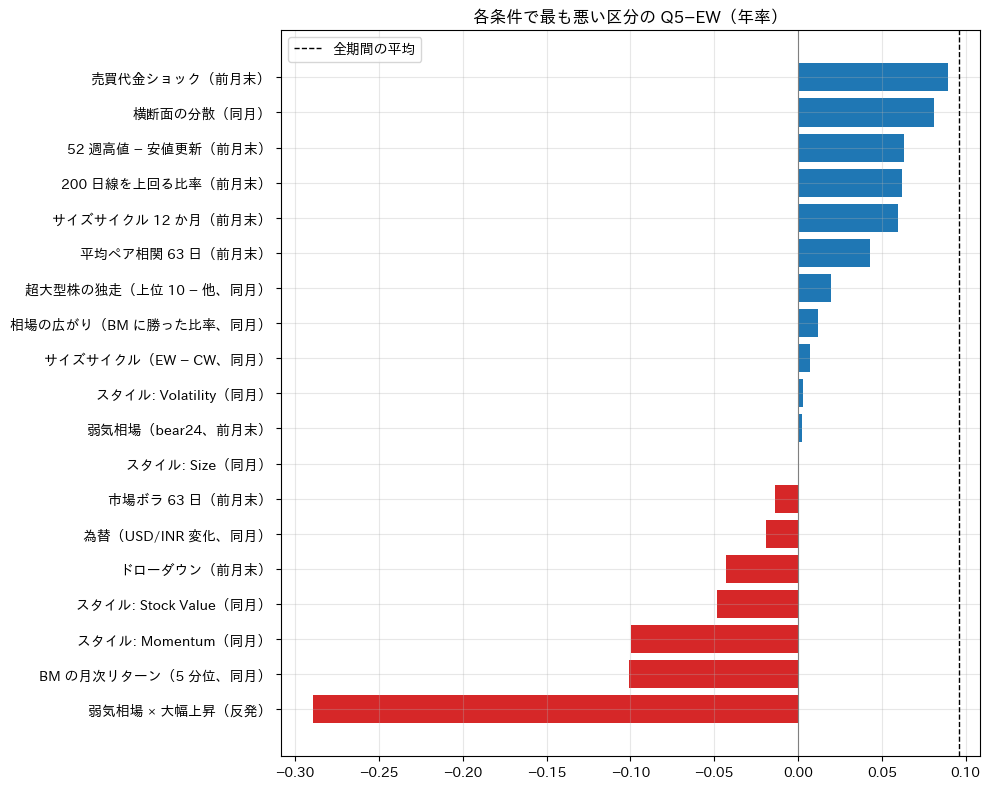

In [16]:
sc = pd.DataFrame(SCORE).set_index("条件")
display(sc.sort_values("最悪 Q5−EW").round(3))
fig, ax = plt.subplots(figsize=(10, 8))
s = sc["最悪 Q5−EW"].sort_values()
ax.barh(s.index, s.to_numpy(), color=np.where(s.to_numpy() < 0, "C3", "C0"))
ax.axvline(
    M["Q5−EW"].mean() * 12, color="k", linestyle="--", linewidth=1, label="全期間の平均"
)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_title("各条件で最も悪い区分の Q5−EW（年率）")
ax.legend()
plt.tight_layout()
plt.show()

## 所見

**結論: `comp_ew` の選択力（Q5 − ユニバース EW）は時期にはきわめて頑健だが、効いているのは小型株の中だけで、市場環境では「リスクオンの急反発」に弱い。弱点は 3 つに分けられる。**
**(1) BM 比の負けはサイズの構造的な賭けによるもので、シグナルの問題ではない。(2) シグナル自体が負けるのは、弱気相場からの反発・バリュー相場・モメンタムの崩れの月。(3) BM の中身である大型・中型の中では、2018 年以降、銘柄選択力がほぼゼロ。**

1. **時期には頑健**: Q5−EW は年率 9.6%（t 6.5）で、**19 年すべてプラス**。IC も全年プラス。12 か月の移動和がマイナスになった窓は 3.6% だけで、最悪は 2009-05 終了の −5.8%。
   IS → OOS で Q5−EW 10.3% → 8.9%（t 4.5）、IC 0.075 → 0.051 と弱まってはいる。Q5−BM は 74% の年でプラスで、マイナスは 2008・2018・2019・2022・2025 年。
2. **弱点 (1) BM 比の負けは構造**: 大型が勝つ月・狭い相場（BM に勝つ銘柄が少ない）・上位 10 銘柄の独走の月は、Q5−BM が年率 −22% / −25% / −11%（t −5〜−8）と大きく負ける。
   それでも Q5−EW は +16% / +12% / +16% と、むしろ平均より高い。2018〜19 年の狭い相場（IL&FS）も Q5−BM −13% に対し Q5−EW +17.5%。
   裏返しで、中小型が勝つ月・広い相場の月は Q5−BM +45% だが Q5−EW はほぼ 0 で、BM 比の勝ちもサイズの賭けから来ている。BM 比の振れの大半は、スタイル回帰でも Size（係数 0.54、t 11.4）が説明する。
3. **弱点 (2) シグナル自体が負ける月**（Q5−EW がマイナスの区分）:
   - **弱気相場からの反発**: 前月末に BM の過去 24 か月が負で、当月が上位 20% の上昇（15 か月）。Q5−EW −28.9%（t −4.7）、Q5−Q1 −72%、IC −0.13。2009 年の反発（Q5−EW −5.5%）、2020-04〜12 のコロナ反発（−6.4%）が該当する。
   - **大幅上昇の月**全般（BM の上位 20%）: Q5−EW −10.1%（t −2.0）。下落が大きい月ほど強い（大幅下落の月 +21.5%、IC 0.15）。
   - **スタイル**: モメンタムが負ける月 −9.9%（t −4.0）、バリューが勝つ月 −4.8%。Q5−EW をスタイルで回帰すると R² 0.70 で、モメンタム +0.27（t 9.7）、バリュー −0.11（t −2.5）、Flow Value +0.08。スタイルで説明できない部分（切片）は年率 3.8%（t 4.4）。
   - **INR 高の月**: Q5−EW −1.9%、INR 安の月 +19.7%（差 t 5.4）。INR 高 = FPI の流入によるリスクオンの月と読める。
   - 共通しているのは「低品質・高ベータ・負け組が買い戻されるリスクオン」。`comp_ew` の選択はモメンタム寄り・バリュー逆張りの性格で、そこが崩れる月に負ける。
4. **月末に分かる状態**（拡大窓の三分位）: 前月末の高ボラ（Q5−EW −1.3%、IC −0.01）・高相関（4.3%、IC 0.002）・ドローダウン −20% 超（−4.3%）・ブレス低（6.2%）・52 週安値更新が多い（6.3%）で弱く、IC の差は t −3.0〜−3.2。`03`・`05` の「ストレス状態ではアクティブリスクを縮める」をロングオンリーの指標でも確認した。
   ただし Q5−EW の差の |t| は 1.7〜2.0 で、区分の月数が偏る（高ボラの三分位は 26 か月）。2003 年以降の拡大窓で、2008 年の高ボラが基準を押し上げているため。
5. **弱点 (3) 大型・中型では効かない**（§7）:
   - 小型株の中: Q5−EW 10.8%（t 6.5）、IC 0.075（IS 0.081 / OOS 0.067）で、全期間・両期間で強い。
   - 大型の中: IC 0.031（IS 0.064 → OOS −0.008）、固有リターンでは OOS −0.038（t −2.3）。中型の中: 0.042（OOS 0.026、t 1.8）。
   - **BM ユニバース（大型 + 中型、平均 88 銘柄）の中: IC は IS 0.062（t 3.3）→ OOS 0.007（t 0.5）、固有リターンでは 0.000。**
   - スリーブ別でも同じで、大型 + 中型の OOS の IC はリビジョン 0.000（IS 0.057）、規律 0.006（IS 0.044）、モメンタム 0.013（IS 0.018）。モメンタムは大型では固有リターンで負（t −2.5）。例外は中型のモメンタム（OOS 0.037、t 2.2）。
   - BM の時価総額の大半を占める銘柄群で、2018 年以降は 3 スリーブとも選択力を失っている。`04` の「モメンタムは小型株の現象」をスリーブ全体に広げた結果。
6. **セクターには頑健**: 11 セクター中 10 で IC が正。一般消費財 0.089・IT 0.085・金融 0.071・資本財 0.066・ヘルスケア 0.057 は IS・OOS とも t > 3。エネルギーだけ効かない（−0.007、IS t −2.0）。素材・公益・生活必需品は OOS で t ≤ 1.1 と弱まる。

**含意**

- **評価の仕方**: `comp_ew` の良し悪しは Q5−BM ではなく Q5−EW・IC で判断する（`healthy_compounder/03` の結論の再確認）。BM 比の年 ±20% の振れはサイズサイクルで、シグナルとは別に管理すべきリスク。
- **アクティブリスクの配分（最重要）**: BM の大半を占める大型・中型では、2018 年以降、`comp_ew` に選択力がない。それでも最適化では大型株のオーバー / アンダーウェイトに TE を使っている。
  大型株ではアルファを 0 に縮める（BM 近傍に保つ）か、大型株専用のモデルを作り、アクティブリスクは小型（と中型のモメンタム）に集中させるのが合理的。狭い相場で超大型株をアンダーウェイトして負ける構造リスクも、同時に減らせる。
- **シグナルのリスク管理**: 負けるのはリスクオンの急反発で、`03`・`05` のストレス状態 / ボラでのアクティブリスクの縮小と、`momentum_regime` の残差モメンタム（弱気局面で崩れない）が、同じ弱点への手当てになる。
- **INR の動き**: INR 安の月は `comp_ew` に追い風、INR 高（FPI 流入）の月は逆風。予測には使えない（同じ月の関係）が、FPI フローがリスクオンの代理になっていることを示す。

**次の候補**

1. **サイズ区分別のアルファの縮小**: bax に渡すアルファを、大型（と中型）で縮める版（例: 大型 0、中型 0.5、小型 1）を作り、TE・IR・税控除後を素の `comp_ew` と比べる。
2. **大型株の選択力の原因調査**: 2018 年以降に大型で何が変わったか（アナリストのカバレッジ増、パッシブ・FPI フロー、リビジョンの情報量の低下）。大型株専用の素材（業種内のリビジョン、ROE の業種間成分、残差モメンタム）を区分内 IC で探す。
3. **反発局面の手当て**: 弱気相場の後の急反発に対して、ストレス状態でベータ・RESVOL を中立化する制約（`03` の候補 2）を、§2.2 の反発月の Q5−EW で評価する。

注意: 同じ月の状態（市場の方向、サイズサイクル、広がり、スタイル、為替）は記述用で、事前には分からない。月末に確定する状態だけがルールに使える。差の t は 2 群の単純な t で、系列相関は補正していない。